In [2]:
from roentgen.absorption import Material
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import ascii
from specutils import Spectrum1D
from astropy.visualization import quantity_support
import numpy as np
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x2544110aaa0>

In [3]:
number_of_detectors = 4
geo_area_detector = 0.81 * u.cm ** 2
meddea_geo_area = number_of_detectors * geo_area_detector

# caliste so properties see https://github.com/i4Ds/STIXCore/blob/master/stixcore/calibration/transmission.py#L18
detector_thickness = 1 * u.mm
det_cathode = Material("Pt", 30 * u.nm)

Load x-class flare data

In [4]:
xclass_spec_file = 'SOL2002-07-23_RHESSI_flare_spectrum.csv'
flare_data = ascii.read(xclass_spec_file)
flare_data.add_index('Bin mean (keV)')
flare_energy = u.Quantity(flare_data['Bin mean (keV)'], 'keV')
flux = u.Quantity(flare_data['Flux (photons/s/cm2/keV)'], 'ph s ** (-1) cm**(-2) keV**(-1)')
flare_spec = Spectrum1D(spectral_axis=flare_energy.to('Hz', equivalencies=u.spectral()), flux=flux)

Text(0.5, 1.0, 'SOL2002-07-23 X4.8 power-law index 2.77')

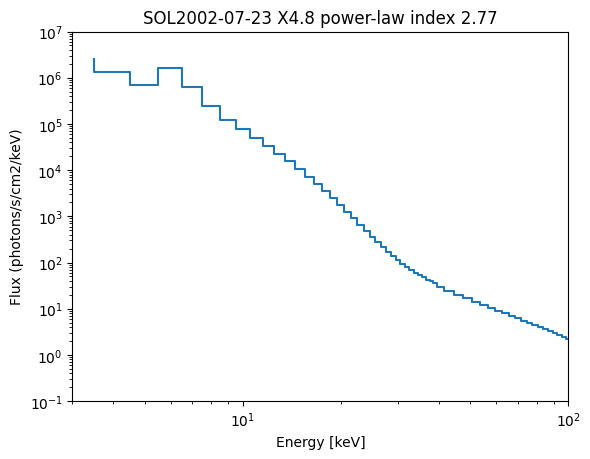

In [5]:
plt.step(flare_spec.energy.to('keV'), flare_spec.flux)
plt.yscale('log')
plt.xscale('log')
plt.xlim(3, 100)
plt.ylim(1e-1, 1e7)
plt.xlabel('Energy [keV]')
plt.ylabel('Flux (photons/s/cm2/keV)')
plt.title("SOL2002-07-23 X4.8 power-law index 2.77")

In [6]:
det_cathode = Material("Pt", 30 * u.nm)
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
detector_area = meddea_geo_area * detector_efficiency
# MLI blankets
MIL_SI = 0.0254 * u.mm
mli_parts = [('al', 1000 * u.angstrom), ('C', 3 * MIL_SI), ('al', 40 * 1000 * u.angstrom),
             ('C', 20 * 0.25 * MIL_SI), ('C', 3 * MIL_SI),
             ('al', 1000 * u.angstrom)]
blankets = Material('C', (3 + 20 * 0.05 + 3) * MIL_SI)
optical_path_no_filters = (blankets).transmission(flare_energy)



[ 5. 30. 30. 90.] keV
[ 5. 30. 30. 90.] keV
[ 5. 30. 30. 90.] keV
[ 5. 30. 30. 90.] keV


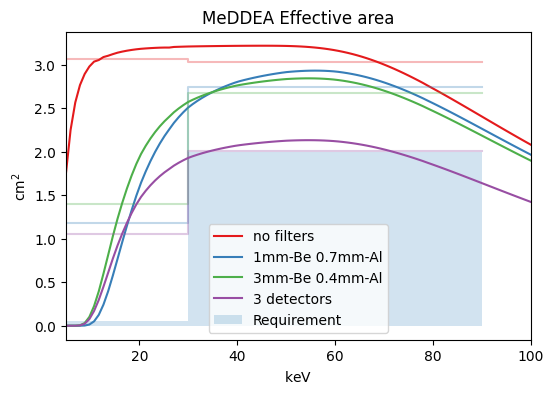

In [7]:
import matplotlib as mpl
name = "Set1"
cmap = mpl.colormaps[name]
colors = cmap.colors

energy = np.linspace(5, 100, 100) * u.keV
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(energy) * det_cathode.transmission(energy)
detector_area = meddea_geo_area * detector_efficiency
optical_path_0 = blankets
optical_path_1 = blankets + Material("Be", thickness=1 * u.mm) + Material("Al", thickness=0.7 * u.mm)
optical_path_2 = blankets + Material("Be", thickness=3 * u.mm) + Material("Al", thickness=0.4 * u.mm)
label = ['no filters', '1mm-Be 0.7mm-Al', '3mm-Be 0.4mm-Al', '3 detectors']

low_erange = [5, 30] * u.keV
hi_erange = [30, 90] * u.keV

plt.figure(figsize=(6, 4))
ax0=plt.subplot(1, 1, 1)
eff_area = [detector_area * optical_path_0.transmission(energy),
            detector_area * optical_path_1.transmission(energy),
            detector_area * optical_path_2.transmission(energy),
            detector_area * optical_path_2.transmission(energy) * 3/4.]

for this_color, this_label, this_eff_area in zip(colors, label, eff_area):
    ax0.plot(energy, this_eff_area, label=this_label, color=this_color)
    eindex = (energy > low_erange[0]) * (energy < low_erange[1])
    low_eff_area_avg = np.mean(this_eff_area[eindex])
    eindex = (energy > hi_erange[0]) * (energy < hi_erange[1])
    high_eff_area_avg = np.mean(this_eff_area[eindex])
    print(u.Quantity([low_erange[0], low_erange[1], hi_erange[0], hi_erange[1]]))
    ax0.plot(u.Quantity([low_erange[0], low_erange[1], hi_erange[0], hi_erange[1]]),
             u.Quantity([low_eff_area_avg, low_eff_area_avg, high_eff_area_avg, high_eff_area_avg]),
             color=this_color, alpha=0.3)



ax0.set_xlim(5, 100)
ax0.set_title('MeDDEA Effective area')
ax0.fill_between((5, 30, 30, 90), (0.05, 0.05, 2, 2), alpha= 0.2, label='Requirement')
ax0.legend()
plt.savefig('cdr_effective_area.png')

In [8]:
colors

((0.8941176470588236, 0.10196078431372549, 0.10980392156862745),
 (0.21568627450980393, 0.49411764705882355, 0.7215686274509804),
 (0.30196078431372547, 0.6862745098039216, 0.2901960784313726),
 (0.596078431372549, 0.3058823529411765, 0.6392156862745098),
 (1.0, 0.4980392156862745, 0.0),
 (1.0, 1.0, 0.2),
 (0.6509803921568628, 0.33725490196078434, 0.1568627450980392),
 (0.9686274509803922, 0.5058823529411764, 0.7490196078431373),
 (0.6, 0.6, 0.6))

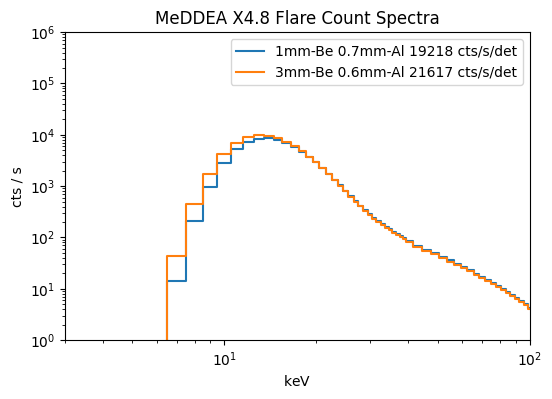

In [9]:
plt.figure(figsize=(6, 4))
ax1=plt.subplot(1, 1, 1)
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
detector_area = meddea_geo_area * detector_efficiency
optical_path_no_filters = (blankets).transmission(flare_energy)


filter_array = [Material("Be", thickness=1 * u.mm).transmission(flare_energy) * Material("Al", thickness=0.7 * u.mm).transmission(flare_energy),
                Material("Be", thickness=3 * u.mm).transmission(flare_energy) * Material("Al", thickness=0.6 * u.mm).transmission(flare_energy),
                ]
label = ['1mm-Be 0.7mm-Al', '3mm-Be 0.6mm-Al']

for this_label, this_filter_arr in zip(label, filter_array):
    xflare_count_spectrum = flare_spec.flux * detector_area * optical_path_no_filters * this_filter_arr
    total_rate = xflare_count_spectrum.sum().value
    ax1.step(flare_energy, xflare_count_spectrum, label=f'{this_label} {total_rate/4:0.0f} cts/s/det')

#ax1.axvspan(10, 60, alpha=0.2, color='grey')
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylabel('cts / s')
ax1.set_xlim(3, 100)
ax1.set_ylim(1, 1e6)
ax1.set_title('MeDDEA X4.8 Flare Count Spectra')
ax1.legend()
plt.savefig('cdr_flare_filters.png')

In [10]:
al_filter_thick = u.Quantity(0.1 * np.arange(1, 10), 'mm')
al_filter_thick

<Quantity [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] mm>

In [11]:
detector_area

<Quantity [2.93923146, 3.07177554, 3.13595097, ..., 0.08435451, 0.08449672,
           0.08463821] cm2>

In [12]:
flare_energy[0:4]

<Quantity [3.5, 4.5, 5.5, 6.5] keV>

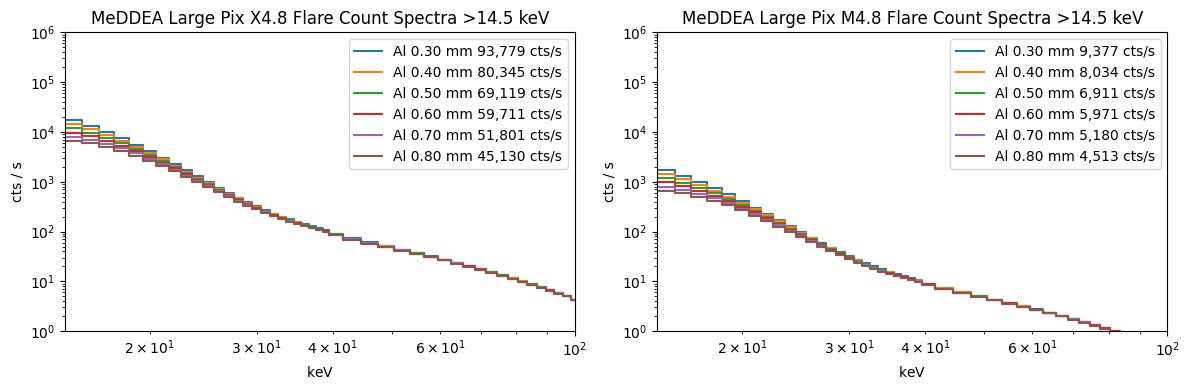

In [13]:
al_filter_thick = u.Quantity(0.1 * np.arange(3, 9), 'mm')

factor = [1, 0.1]
flare_str = ['X', 'M']
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    ax1=plt.subplot(1, 2, i+1)
    min_energy_index = 11
    detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
    detector_area = meddea_geo_area * detector_efficiency
    optical_path_no_filters = (blankets).transmission(flare_energy)

    for this_thick in al_filter_thick:
        xflare_count_spectrum = factor[i] * flare_spec.flux * detector_area * optical_path_no_filters * Material("Be", thickness=1 * u.mm).transmission(flare_energy)
        xflare_count_spectrum *= Material("Al", thickness=this_thick).transmission(flare_energy)
        total_rate = xflare_count_spectrum[min_energy_index:].sum().value
        ax1.step(flare_energy, xflare_count_spectrum, label=f'Al {this_thick:0.2f} {int(total_rate):,} cts/s')

    #ax1.axvspan(10, 60, alpha=0.2, color='grey')
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_ylabel('cts / s')
    ax1.set_xlim(flare_energy[min_energy_index].value, 100)
    ax1.set_ylim(1, 1e6)
    ax1.set_title(f'MeDDEA Large Pix {flare_str[i]}4.8 Flare Count Spectra >{flare_energy[min_energy_index]}')
    ax1.legend(loc=1)
fig.tight_layout()


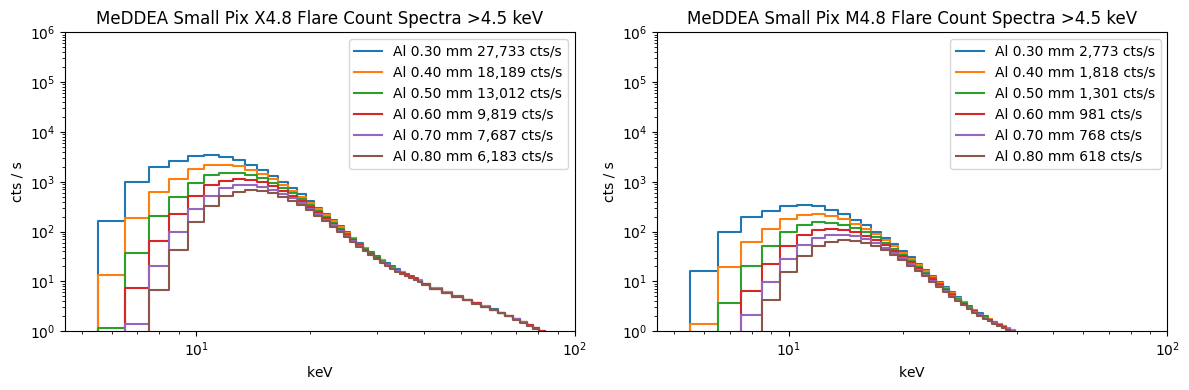

In [14]:
al_filter_thick = u.Quantity(0.1 * np.arange(3, 9), 'mm')

factor = [0.1, 0.01]
flare_str = ['X', 'M']
fig = plt.figure(figsize=(12, 4))
for i in range(2):
    ax1=plt.subplot(1, 2, i+1)
    min_energy_index = 1
    detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
    detector_area = meddea_geo_area * detector_efficiency
    optical_path_no_filters = (blankets).transmission(flare_energy)

    for this_thick in al_filter_thick:
        xflare_count_spectrum = factor[i] * flare_spec.flux * detector_area * optical_path_no_filters * Material("Be", thickness=1 * u.mm).transmission(flare_energy)
        xflare_count_spectrum *= Material("Al", thickness=this_thick).transmission(flare_energy)
        total_rate = xflare_count_spectrum[min_energy_index:].sum().value
        ax1.step(flare_energy, xflare_count_spectrum, label=f'Al {this_thick:0.2f} {int(total_rate):,} cts/s')

    #ax1.axvspan(10, 60, alpha=0.2, color='grey')
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.set_ylabel('cts / s')
    ax1.set_xlim(flare_energy[min_energy_index].value, 100)
    ax1.set_ylim(1, 1e6)
    ax1.set_title(f'MeDDEA Small Pix {flare_str[i]}4.8 Flare Count Spectra >{flare_energy[min_energy_index]}')
    ax1.legend(loc=1)
fig.tight_layout()

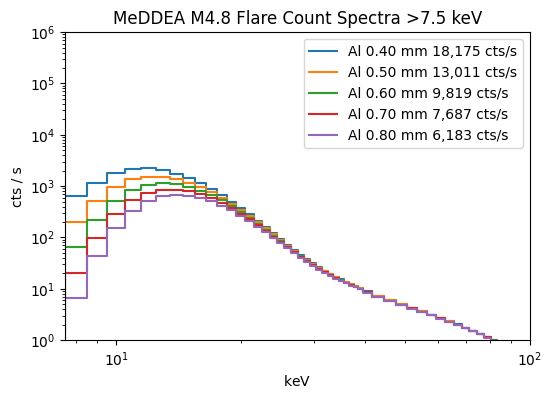

In [15]:
al_filter_thick = u.Quantity(0.1 * np.arange(4, 9), 'mm')

plt.figure(figsize=(6, 4))
ax1=plt.subplot(1, 1, 1)
min_energy_index = 4
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
detector_area = meddea_geo_area * detector_efficiency
optical_path_no_filters = (blankets).transmission(flare_energy)

for this_thick in al_filter_thick:
    xflare_count_spectrum = 0.1 * flare_spec.flux * detector_area * optical_path_no_filters * Material("Be", thickness=1 * u.mm).transmission(flare_energy)
    xflare_count_spectrum *= Material("Al", thickness=this_thick).transmission(flare_energy)
    total_rate = xflare_count_spectrum[min_energy_index:].sum().value
    ax1.step(flare_energy, xflare_count_spectrum, label=f'Al {this_thick:0.2f} {int(total_rate):,} cts/s')

#ax1.axvspan(10, 60, alpha=0.2, color='grey')
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylabel('cts / s')
ax1.set_xlim(flare_energy[min_energy_index].value, 100)
ax1.set_ylim(1, 1e6)
ax1.set_title(f'MeDDEA M4.8 Flare Count Spectra >{flare_energy[min_energy_index]}')
ax1.legend(loc=1)

In [16]:
from astropy.table import Table
t = Table()
t['al thickness'] = al_filter_thick
total_rate_x = []
for this_thick in al_filter_thick:
    xflare_count_spectrum = flare_spec.flux * detector_area * optical_path_no_filters * Material("Be", thickness=1 * u.mm).transmission(flare_energy)
    xflare_count_spectrum *= Material("Al", thickness=this_thick).transmission(flare_energy)
    total_rate_x.append(xflare_count_spectrum[1:].sum().value)
t['x class'] = total_rate * u.count/u.s
t['m class'] = total_rate * u.count/u.s / 10.0
t['c class'] = total_rate * u.count/u.s / 100.0
print(t)


   al thickness         x class           m class           c class     
        mm               ct / s            ct / s            ct / s     
------------------ ----------------- ----------------- -----------------
               0.4 6183.401922172898 618.3401922172898 61.83401922172898
               0.5 6183.401922172898 618.3401922172898 61.83401922172898
0.6000000000000001 6183.401922172898 618.3401922172898 61.83401922172898
0.7000000000000001 6183.401922172898 618.3401922172898 61.83401922172898
               0.8 6183.401922172898 618.3401922172898 61.83401922172898


In [137]:
bin_edges = [3.5, 7, 12, 15, 20, 30, 60, 110, 150] * u.keV

min_energy_index = 0
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
detector_area = meddea_geo_area * detector_efficiency
optical_path_no_filters = (blankets).transmission(flare_energy)

xflare_count_spectrum = 0.1 * flare_spec.flux * detector_area * optical_path_no_filters * Material("Be", thickness=1 * u.mm).transmission(flare_energy)
xflare_count_spectrum *= Material("Al", thickness=al_filter_thick).transmission(flare_energy)
total_rate = xflare_count_spectrum[min_energy_index:].sum().value


In [138]:
from scipy.interpolate import interp1d
import scipy.integrate as integrate

In [139]:
f = interp1d(np.log10(flare_energy.value), np.log10(xflare_count_spectrum.value), fill_value=0)
def flare(x):
    return 10**f(np.log10(x))


C:\Users\sdchris1\AppData\Local\Temp\1\ipykernel_28028\1247254699.py:1: RuntimeWarning: invalid value encountered in log10
  f = interp1d(np.log10(flare_energy.value), np.log10(xflare_count_spectrum.value), fill_value=0)


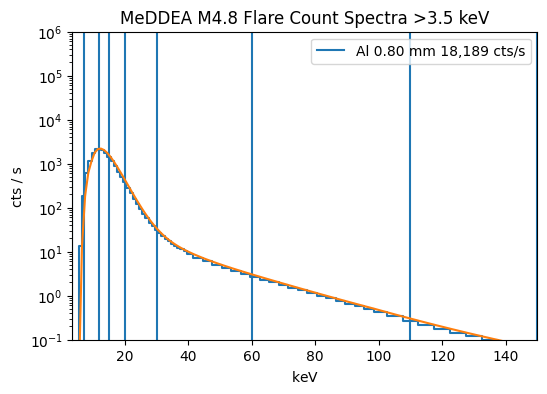

In [140]:
al_filter_thick = u.Quantity(0.4, 'mm')

plt.figure(figsize=(6, 4))
ax1=plt.subplot(1, 1, 1)
ax1.step(flare_energy, xflare_count_spectrum, label=f'Al {this_thick:0.2f} {int(total_rate):,} cts/s')

for this_edge in bin_edges:
    ax1.axvline(this_edge.value)
ax1.plot(flare_energy, flare(flare_energy.value))
#ax1.axvspan(10, 60, alpha=0.2, color='grey')
ax1.set_yscale('log')
ax1.set_ylabel('cts / s')
ax1.set_xlim(flare_energy[min_energy_index].value, 150)
ax1.set_ylim(0.1, 1e6)
ax1.set_title(f'MeDDEA M4.8 Flare Count Spectra >{flare_energy[min_energy_index]}')
ax1.legend(loc=1)

In [154]:
bin_str = []
bin = []
cts_s = []
cts_inter_s = []
for i, this_edge in enumerate(bin_edges[1:]):
    tbl = Table()
    ind = (flare_energy > bin_edges[i]) * (flare_energy < this_edge)
    print(f"{bin_edges[i]}-{this_edge}")
    print(f"{flare_energy[ind].min()}-{flare_energy[ind].max()}")
    bin_str.append(f"{flare_energy[ind].min()}-{flare_energy[ind].max()}")
    bin.append(i)
    cts_inter_s.append(integrate.quad(flare, bin_edges[i].value, this_edge.value)[0])
    cts_s.append(xflare_count_spectrum[ind].sum().value)

tbl['bin_str'] = bin_str
tbl['bin start'] = bin_edges[:-1]
tbl['bin'] = bin
tbl['cts_s'] = cts_s
tbl['cts_inter_s'] = cts_inter_s


3.5 keV-7.0 keV
4.5 keV-6.5 keV
7.0 keV-12.0 keV
7.5 keV-11.5 keV
12.0 keV-15.0 keV
12.5 keV-14.5 keV
15.0 keV-20.0 keV
15.5 keV-19.5 keV
20.0 keV-30.0 keV
20.5 keV-29.5 keV
30.0 keV-60.0 keV
30.5 keV-59.5 keV
60.0 keV-110.0 keV
62.5 keV-107.5 keV
110.0 keV-150.0 keV
112.5 keV-147.5 keV


C:\Users\sdchris1\AppData\Local\Temp\1\ipykernel_28028\202236231.py:12: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  cts_inter_s.append(integrate.quad(flare, bin_edges[i].value, this_edge.value)[0])


In [155]:
tbl['fraction'] = tbl['cts_s'] / tbl['cts_s'].sum()
tbl['decim_frac'] = [0.5, 0.5, 0.5, 0.5, 0.75, 1, 1, 0.1]
tbl['decimated'] = tbl['decim_frac'] * tbl['cts_s']
tbl

bin_str,bin start,bin,cts_s,cts_inter_s,fraction,decim_frac,decimated
,keV,,,,,,
str19,float64,int32,float64,float64,float64,float64,float64
4.5 keV-6.5 keV,3.5,0,13.65272900054811,16.65693001325414,0.0007506006330290936,0.5,6.826364500274055
7.5 keV-11.5 keV,7.0,1,5902.5326461411405,5787.558007167898,0.32450982807104456,0.5,2951.2663230705703
12.5 keV-14.5 keV,12.0,2,5986.181187888697,5929.211033791264,0.32910866310140047,0.5,2993.0905939443487
15.5 keV-19.5 keV,15.0,3,4594.509020373892,4588.927071962116,0.2525972191356082,0.5,2297.254510186946
20.5 keV-29.5 keV,20.0,4,1455.304026040839,1459.4519143473135,0.08000980046935584,0.75,1091.4780195306294
30.5 keV-59.5 keV,30.0,5,217.78459250256387,291.93331651812474,0.011973375651845496,1.0,217.78459250256387
62.5 keV-107.5 keV,60.0,6,17.925360494255287,58.313610609304696,0.000985501648331448,1.0,17.925360494255287
112.5 keV-147.5 keV,110.0,7,1.182495027169979,5.9229169567582405,6.501128938484812e-05,0.1,0.11824950271699791


The above decimation fractions lead to a halving of the flux as can be seen below. Also the bin edges are set to try to equalize the flux in each bin in the thermal regime. Bin 0 should really be 0 but this data set does not allow that value. Decimations levels above this one should take these fractions and divide each be 2 so that the higher level halfs the flux again.

In [160]:
np.sum(tbl['decim_frac'] * tbl['cts_inter_s']) / np.sum(tbl['cts_inter_s'])

0.5296404246480346

In [157]:
tbl.remove_column('bin_str')
tbl.remove_column('cts_s')

In [158]:
tbl.write('lvl1_flare_decimation.csv', format='csv', overwrite=True)